# Enzyme Design Pipeline
MH - 10/01/2026
KS - 21/01/2026
```
RFD3 → MPNN → RF3
```

This notebook is for designing enzymes from a known theozyme. 

## Create environment

### Install miniforge

Download miniforge3 and install it at your net scratch `/work3/$USER/` with:

```
cd /work3/$USER/
curl -L -O "https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-$(uname)-$(uname -m).sh"
bash Miniforge3-$(uname)-$(uname -m).sh
```

You can decide whether you want to auto-initialize the environment or not in the installation options. Before installing the environment make sure the conda base environment is activated. If it is activated your terminal should look something like this:

```
(base) /work3/user/projects/enzyme_design
hpclogin1(user) $ 
```

### install the enzyme design environment

This notebook is designed to run in the cgrp_env1 Conda environment, which already contains all required packages. You only need to register this environment as a Jupyter kernel once.

```
conda env create -f enzdes.yml
conda activate enzdes
python -m ipykernel install --user \
  --name cgrp_env1 \
  --display-name "enzdes"
```
Then, in Jupyter, select:
```
Kernel → enzdes
```
After that, you can run all cells in this notebook normally. You may need to restart your IDE if it does not show up immediately.

### Set Up: imports and directories

In [1]:
enzdes_scripts = '/work3/s253573/DBL_secrets/enzdes_pipeline-main'  # edit if path differs

# --- Core ---
import os, sys, re, glob, json, math, shutil, random, string, csv
import itertools
from pathlib import Path
from collections import Counter, defaultdict, OrderedDict
from datetime import datetime
from copy import deepcopy
from Bio import SeqIO
sys.path.insert(0, enzdes_scripts)
import jupyter_utils

# --- Data / numerics ---
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

# --- Plotting ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Notebook display ---
from IPython.display import display

In [2]:
user     = os.environ.get('USER', '')
family   = 'atp_binding'       # enzyme family  (e.g. hydrolases, oxidoreductases)
target   = 'conditioned_assembly' # enzyme target
campaign = '8btg_D501_v3'              # campaign / round identifier

working_dir = f'/work3/{user}/projects/enzyme_design/{family}/{target}/{campaign}'
os.makedirs(working_dir, exist_ok=True)
os.chdir(working_dir)

def setup_directories(base_dir, dirs_list):
    """Create subdirectories and return a dict mapping <name>_dir → full path."""
    result = {}
    for dir_name in dirs_list:
        full_path = os.path.join(base_dir, dir_name)
        os.makedirs(full_path, exist_ok=True)
        result[dir_name + '_dir'] = full_path
    return result

wrk_dirs_list = ['cmds', 'logs', 'pics', 'configs', 'scores', 'inputs',
                 'diffusion_out', 'rf3_out', 'mpnn_out']
_dirs = setup_directories(working_dir, wrk_dirs_list)

cmds_dir         = _dirs['cmds_dir']
logs_dir         = _dirs['logs_dir']
pics_dir         = _dirs['pics_dir']
configs_dir      = _dirs['configs_dir']
scores_dir       = _dirs['scores_dir']
inputs_dir       = _dirs['inputs_dir']
diffusion_out_dir = _dirs['diffusion_out_dir']
rf3_out_dir      = _dirs['rf3_out_dir']
mpnn_out_dir     = _dirs['mpnn_out_dir']

print(f"Campaign : {family} / {target} / {campaign}")
print(f"Directory: {working_dir}")

Campaign : atp_binding / conditioned_assembly / 8btg_D501_v3
Directory: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3


### RFD3

RFdiffusion3 (RFD3) generates de novo backbone structures by diffusing from noise under constraints you define — here, the catalytic residues are fixed in their theozyme geometry while the surrounding scaffold is designed freely.

Full parameter reference: [RFD3 enzyme design docs](https://github.com/RosettaCommons/foundry/blob/production/models/rfd3/docs/enzyme_design.md)

Key parameters to configure below:
- **`contig`**: scaffold layout — free segments like `30-50` are designed from scratch; entries like `A58-58` copy a residue directly from the input PDB. Commas separate segments; `/0` separates chains.
- **`fixed_residues`**: protein residues to hold fixed during MPNN sequence design. Leave empty `[]` for pure binder / de-novo design. For enzyme design, populate with residue IDs in the *diffused output* structure (e.g. `["A5", "A12"]`); use `data['diffused_index_map']` in the RFD3 output JSON to remap from input PDB numbering if needed.
- **`fixed_atoms`**: specific sidechain atoms to pin in place *during diffusion* (preserves catalytic geometry); only relevant when motif residues are included in the contig.
- **`ligand_name`**: must match the residue name in your input PDB (can be an arbitrary label for non-CCD ligands).

In [3]:
dialect   = 2
input_pdb = f'{working_dir}/inputs/ATP_binding_8btg.cif'

# Scaffold layout: free ranges (e.g. 30-50) interspersed with fixed motif residues (e.g. A58-58)
contig = "20-30,D151-D159,3-8,D120-123,20-30,/0,20-30,D287-D289,20-30,D312-D314,10-20,C259-C265,20-30"

# Total design length range (residues)
length = "136-203"

ligand_name              = "ATP"   # must match residue name in input PDB
redesign_motif_sidechains = False
is_non_loopy             = True    # biases diffusion toward helices; reduces loop content
infer_ori_strategy       = None    # use "hotspots" for binder design; None for enzyme design
hotspots                 = None

# Protein residues to hold fixed during MPNN sequence design.
# Leave empty for pure binder / de-novo design.
# For enzyme design: populate with residue IDs in the diffused output structure
# (e.g. ["A5", "A12"]). Use data['diffused_index_map'] in the RFD3 output JSON
# to remap from original input PDB numbering to diffused output numbering.
#fixed_residues = ["D121", "D152", "D154", "D155", "D156", "D157", "D158", "D159", "D288", "D313", "C260", "C264"]

# Key sidechain atoms to pin during diffusion (preserves catalytic geometry)
fixed_atoms = {
    "D121": "N,O",
    "D152": "O",
    "D154": "N",
    "D155": "N",
    "D156": "CA,C,N",
    "D157": "N,NZ",
    "D158": "N,OG1",
    "D159": "N,ND1",
    "D288": "NZ",
    "D313": "NH1,NH2",
    "C260": "NH1,NH2",
    "C264": "NH1,NH2",
    }
select_hotspots       = {}
select_hbond_donor    = {}
select_hbond_acceptor = {}
fixed_residues = {}

In [4]:
cmds      = f'{cmds_dir}/rfd3.cmds'
ckpt_path = "/dtu/projects/dbl/foundry/ckpt/rfd3_latest.ckpt"
diffusion_batch_size = 10
n_batches = 10

with open(cmds, 'w') as f:
    bn = os.path.basename(input_pdb)[:-4]

    # write config json
    json_f = f'{configs_dir}/{bn}.json'
    jupyter_utils.write_rfd3_json(json_f, input_pdb, contig, length,
                                  ligand=ligand_name,
                                  fixed_atoms=fixed_atoms, dialect=dialect,
                                  redesign_motif_sc=redesign_motif_sidechains,
                                  hotspots=hotspots, infer_ori_strategy=infer_ori_strategy)

    outdir = f'{diffusion_out_dir}/{bn}'
    os.makedirs(outdir, exist_ok=True)

    cmd = f'rfd3 design \
                out_dir={outdir} \
                inputs={json_f} \
                ckpt_path={ckpt_path} \
                diffusion_batch_size={diffusion_batch_size} \
                n_batches={n_batches} \
                inference_sampler.step_scale=3 \
                inference_sampler.gamma_0=0.2'
    f.write(cmd + '\n')

n_task = len(open(cmds).readlines())
jupyter_utils.make_sub_script(cmds=cmds, n_task=n_task, mem='10GB', time_limit='12:30',
                              cores=4, gpu='num=1:mode=exclusive_process',
                              queue='gpul40s', job_name='rfd3',
                              env='/dtu/projects/dbl/foundry/miniforge3/envs/rfd3',
                              python_path='/dtu/projects/dbl/foundry')

sub_script = cmds.replace('.cmds', '.sh')
print(f"Generated {n_task} RFD3 job(s).")
print(f"\nSubmit with:\n  bsub < {sub_script}\n")

Generated 1 RFD3 job(s).

Submit with:
  bsub < /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/cmds/rfd3.sh



#### Process rfd3 outputs

In [5]:
rfd3_metrics_csv = f'{scores_dir}/rfd3_metrics_with_json_path.csv'

json_paths = sorted(glob.glob(f'{diffusion_out_dir}/*/*json'))
if not json_paths:
    raise SystemExit("No JSON files found — run RFD3 jobs first.")

rows = []
all_keys = set(["json_path"])

for jp in json_paths:
    with open(jp, "r") as f:
        data = json.load(f)

    metrics = data.get("metrics", {})
    row = {"json_path": os.path.abspath(jp)}
    for k, v in metrics.items():
        if k in ("diffused_com", "fixed_com") and isinstance(v, (list, tuple)) and len(v) == 3:
            row[f"{k}_x"], row[f"{k}_y"], row[f"{k}_z"] = v
            all_keys.update({f"{k}_x", f"{k}_y", f"{k}_z"})
        else:
            row[k] = v
            all_keys.add(k)
    rows.append(row)

fieldnames = ["json_path"] + sorted(k for k in all_keys if k != "json_path")

with open(rfd3_metrics_csv, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    for r in rows:
        writer.writerow(r)

print(f"Wrote {len(rows)} rows → {rfd3_metrics_csv}")
print("Columns:", fieldnames)

Wrote 100 rows → /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/scores/rfd3_metrics_with_json_path.csv
Columns: ['json_path', 'alanine_content', 'diffused_com_x', 'diffused_com_y', 'diffused_com_z', 'fixed_com_x', 'fixed_com_y', 'fixed_com_z', 'glycine_content', 'helix_fraction', 'loop_fraction', 'max_ca_deviation', 'n_chainbreaks', 'n_clashing.interresidue_clashes_w_backbone', 'n_clashing.interresidue_clashes_w_sidechain', 'n_clashing.ligand_clashes', 'n_clashing.ligand_min_distance', 'non_loop_fraction', 'num_residues', 'num_ss_elements', 'radius_of_gyration', 'sheet_fraction']


#### Inspect metrics

Review RFD3 output quality before moving to MPNN. Key columns:
- **`n_chainbreaks`**: must be 0 — broken chains are discarded before sequence design
- **`loop_fraction`**: lower is generally better; `is_non_loopy=True` above reduces this
- **`n_clashing.*`**: clash counts; structures with clashes are filtered before MPNN

In [6]:
df = pd.read_csv(rfd3_metrics_csv)
df.head(10)

,json_path,alanine_content,diffused_com_x,diffused_com_y,diffused_com_z,fixed_com_x,fixed_com_y,fixed_com_z,glycine_content,helix_fraction,...,n_chainbreaks,n_clashing.interresidue_clashes_w_backbone,n_clashing.interresidue_clashes_w_sidechain,n_clashing.ligand_clashes,n_clashing.ligand_min_distance,non_loop_fraction,num_residues,num_ss_elements,radius_of_gyration,sheet_fraction
0,/work3/s253573/projects/enzyme_design/atp_bind...,0.452229,0.488218,1.347103,1.894757,-0.000097,0.00119,-0.000078,0.076433,0.586667,...,1,0,0,0,3.404738,0.586667,157,7,15.118001,0.000000
1,/work3/s253573/projects/enzyme_design/atp_bind...,0.420382,0.383132,1.471291,3.118763,-0.000097,0.00119,-0.000078,0.070064,0.506667,...,1,0,0,0,3.334305,0.693333,157,10,15.030496,0.186667
2,/work3/s253573/projects/enzyme_design/atp_bind...,0.452229,-1.405873,1.299417,2.535992,-0.000097,0.00119,-0.000078,0.076433,0.513333,...,2,0,6,0,2.625736,0.660000,157,9,14.306105,0.146667
3,/work3/s253573/projects/enzyme_design/atp_bind...,0.394904,2.599527,1.350568,2.497499,-0.000097,0.00119,-0.000078,0.063694,0.620000,...,1,0,2,0,2.948840,0.680000,157,7,15.660701,0.060000
4,/work3/s253573/projects/enzyme_design/atp_bind...,0.452229,0.369369,2.715905,0.528743,-0.000097,0.00119,-0.000078,0.108280,0.693333,...,2,0,0,0,2.405106,0.733333,157,9,15.544805,0.040000
5,/work3/s253573/projects/enzyme_design/atp_bind...,0.445860,1.656167,0.649275,2.272452,-0.000097,0.00119,-0.000078,0.050955,0.486667,...,1,0,0,0,3.778436,0.646667,157,10,14.830409,0.160000
6,/work3/s253573/projects/enzyme_design/atp_bind...,0.401274,-0.227390,2.197564,1.980793,-0.000097,0.00119,-0.000078,0.070064,0.540000,...,1,0,3,0,3.491899,0.686667,157,10,14.663812,0.146667
7,/work3/s253573/projects/enzyme_design/atp_bind...,0.445860,1.647573,1.701704,0.550776,-0.000097,0.00119,-0.000078,0.089172,0.526667,...,1,0,0,0,2.836807,0.566667,157,7,15.028366,0.040000
8,/work3/s253573/projects/enzyme_design/atp_bind...,0.528662,1.435192,1.939237,2.068858,-0.000097,0.00119,-0.000078,0.076433,0.713333,...,1,0,0,0,3.017421,0.746667,157,9,16.618598,0.033333
9,/work3/s253573/projects/enzyme_design/atp_bind...,0.515924,2.207042,1.241820,1.124762,-0.000097,0.00119,-0.000078,0.063694,0.573333,...,1,0,0,0,2.235245,0.573333,157,7,15.102266,0.000000


Plotting: ['alanine_content', 'glycine_content', 'helix_fraction', 'loop_fraction', 'sheet_fraction', 'max_ca_deviation', 'n_chainbreaks', 'n_clashing.interresidue_clashes_w_backbone', 'n_clashing.interresidue_clashes_w_sidechain', 'non_loop_fraction', 'radius_of_gyration']


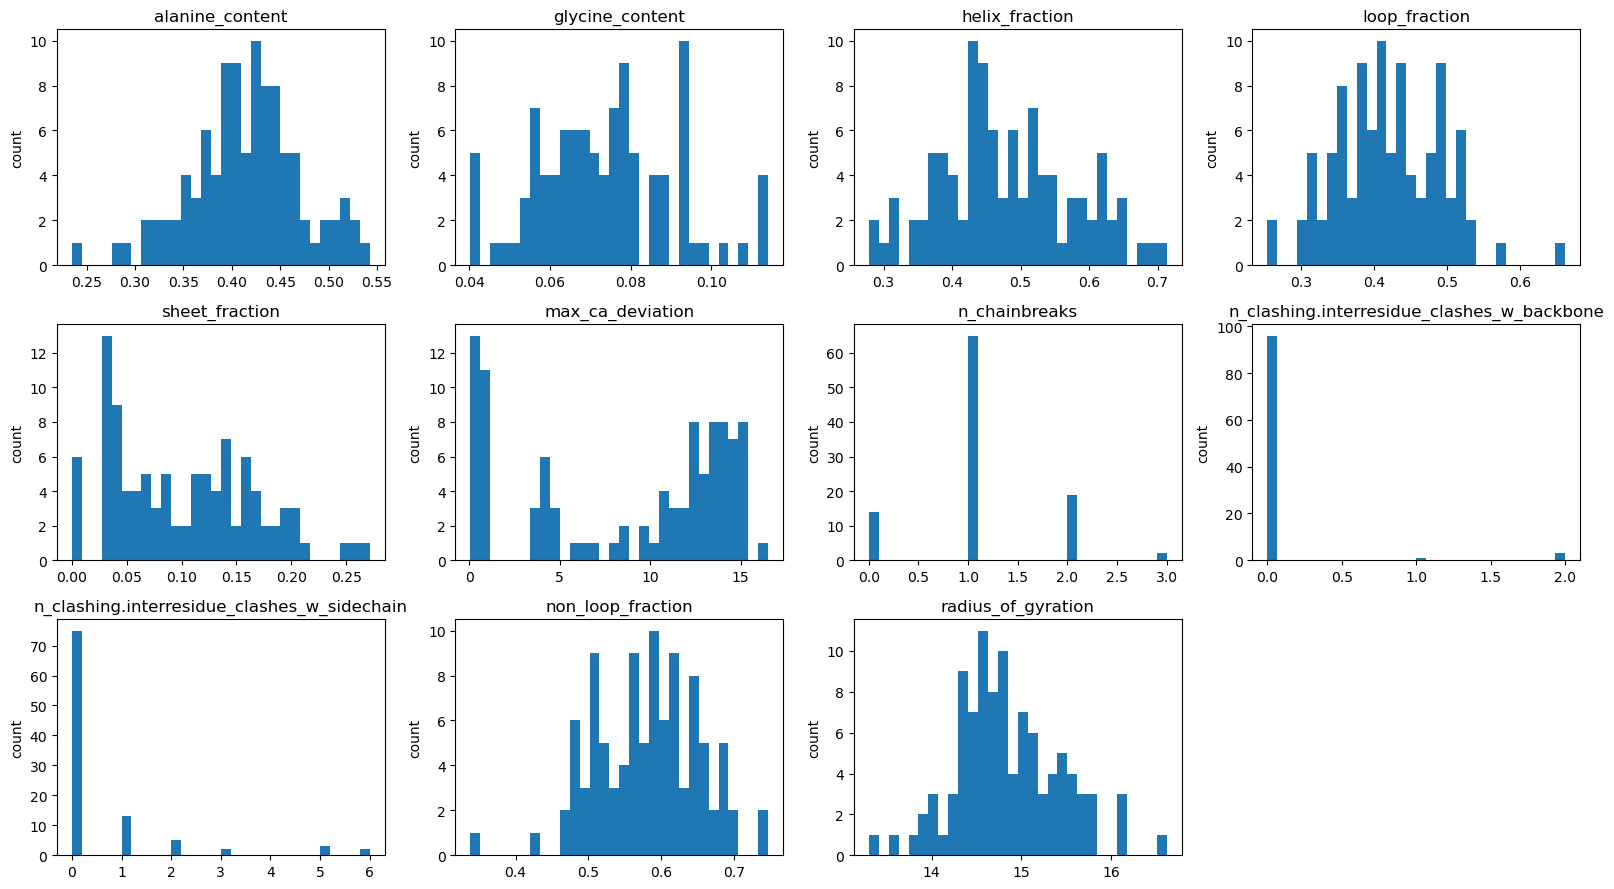

In [7]:
metrics = [
    "alanine_content",
    "glycine_content",
    "helix_fraction",
    "loop_fraction",
    "sheet_fraction",
    "max_ca_deviation",
    "n_chainbreaks",
    "n_clashing.interresidue_clashes_w_backbone",
    "n_clashing.interresidue_clashes_w_sidechain",
    "non_loop_fraction",
    "radius_of_gyration",
]

# Keep only columns that exist (safety)
metrics = [m for m in metrics if m in df.columns]

print("Plotting:", metrics)

n_metrics = len(metrics)
n_cols = 4
n_rows = math.ceil(n_metrics / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.flatten()

def plot_hist(ax, series, title):
    s = series.dropna()
    if s.empty:
        ax.set_title(f"{title} (no data)")
        ax.axis("off")
        return
    ax.hist(s, bins=30)
    ax.set_title(title)
    ax.set_ylabel("count")

for ax, col in zip(axes, metrics):
    plot_hist(ax, df[col], col)

# Turn off unused axes
for ax in axes[len(metrics):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### MPNN

LigandMPNN designs amino acid sequences onto each generated backbone, conditioning on the small-molecule ligand context. Any residues in `fixed_residues` are kept fixed; leave it empty to design the full scaffold freely. Structures with chain breaks or clashes are discarded before sequence design.

In [8]:
seed              = 42
batch_size        = 10   # sequences per structure
number_of_batches = 1    # total sequences per design = batch_size × number_of_batches
ckpt              = '/dtu/projects/dbl/LigandMPNN/25.3.1-0//model_params/ligandmpnn_v_32_010_25.pt'
chains_to_design  = 'A,B'  # chain(s) to redesign; fixed_residues will be kept fixed regardless
remove_bad_structures = True

In [9]:
sys.path.append("/dtu/projects/dbl/proteusai/latest/src/")
from pai.metrics.structure import compute_structure_metrics
from atomworks.io import parse

Environment variable CCD_MIRROR_PATH not set. Will not be able to use function requiring this variable. To set it you may:
  (1) add the line 'export VAR_NAME=path/to/variable' to your .bashrc or .zshrc file
  (2) set it in your current shell with 'export VAR_NAME=path/to/variable'
  (3) write it to a .env file in the root of the atomworks.io repository
Environment variable PDB_MIRROR_PATH not set. Will not be able to use function requiring this variable. To set it you may:
  (1) add the line 'export VAR_NAME=path/to/variable' to your .bashrc or .zshrc file
  (2) set it in your current shell with 'export VAR_NAME=path/to/variable'
  (3) write it to a .env file in the root of the atomworks.io repository


In [10]:
import gzip as _gzip

def _motif_residues_from_cif(cif_gz_path):
    """Return space-separated 'ChainRes' string of motif residues (is_motif_atom_with_fixed_seq=True)."""
    seen, order = set(), []
    with _gzip.open(cif_gz_path, 'rt') as fh:
        for line in fh:
            if not line.startswith('ATOM'):
                continue
            parts = line.split()
            if len(parts) < 18 or parts[17] != 'True':
                continue
            key = (parts[11], int(parts[9]))   # (auth_asym_id, auth_seq_id)
            if key not in seen:
                seen.add(key)
                order.append(key)
    order.sort()
    return ' '.join(f'{c}{r}' for c, r in order)

cmds = f'{cmds_dir}/mpnn.cmds'
bad_structure_count = 0

with open(cmds, 'w') as f:
    for structure in sorted(glob.glob(f'{diffusion_out_dir}/*/*cif.gz')):
        if remove_bad_structures:
            struct = parse(structure)
            metrics = compute_structure_metrics(struct["asym_unit"][0])
            if metrics["n_chainbreaks"] >1 or metrics["n_clashes_sidechain"] > 0 or metrics["n_clashes_backbone"] > 0:
                bad_structure_count += 1
                continue

        bn = os.path.basename(structure).replace('.cif.gz', '').replace('.pdb', '')
        this_outdir = f'{mpnn_out_dir}/{bn}'
        os.makedirs(this_outdir, exist_ok=True)

        fixed_resis = _motif_residues_from_cif(structure)

        cmd = f'python /dtu/projects/dbl/LigandMPNN/25.3.1-0/run.py \
                --seed {seed} \
                --pdb_path "{structure}" \
                --out_folder "{this_outdir}" \
                --fixed_residues "{fixed_resis}" \
                --batch_size {batch_size} \
                --number_of_batches {number_of_batches} \
                --model_type "ligand_mpnn" \
                --checkpoint_ligand_mpnn "{ckpt}" \
                --chains_to_design "{chains_to_design}" '
        f.write(cmd + '\n')

print(f'Removed {bad_structure_count} structures with clashes or chain breaks before design.')

n_tasks = len(open(cmds).readlines())
jupyter_utils.make_sub_script(cmds, n_task=n_tasks, group_size=10, mem='10G', queue='hpc',
                              job_name='mpnn', cores=4, time_limit='2:00',
                              python_path='/dtu/projects/dbl/LigandMPNN/25.3.1-0/',
                              env='/dtu/projects/dbl/LigandMPNN/25.3.1-0//miniforge3/envs/ligandmpnn_env')

sub_script = cmds.replace('.cmds', '.sh')
print(f"Generated {n_tasks} MPNN job(s).")
print(f"\nSubmit with:\n  bsub < {sub_script}\n")


Removed 24 structures with clashes or chain breaks before design.
Generated 76 MPNN job(s).

Submit with:
  bsub < /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/cmds/mpnn.sh



### RF3

RosettaFold3 (RF3) predicts the full all-atom structure of each MPNN-designed sequence in complex with the ligand. This is the validation step — high pLDDT and low PAE indicate a confident, well-packed design.

The script below iterates over all MPNN FASTA files, skips the first sequence (the original RFD3 backbone with alanine fill), and writes one RF3 JSON per designed sequence into `configs/rf3/`.

#### Create cmds

In [11]:
# Ligand specification for RF3
# RF3 accepts three formats (best → worst accuracy per RF3 docs):
#   1. CCD code    — set ccd_ligand=True, provide ligand_name matching CCD (e.g. "ATP", "HEM")
#   2. SDF / CIF   — set sdf_path to an absolute path; RF3 auto-assigns atom names
#   3. SMILES      — fallback; ensure chirality is encoded correctly

ligand_name = "ATP"    # must match residue name in your input PDB / RFD3 output
ccd_ligand  = False    # True if ligand has a standard CCD code (e.g. "ATP", "HEM")
sdf_path    = f'{inputs_dir}/cluster_01_top1_8BTG_D_501.cif'   # path to SDF file; set to None to use SMILES
smiles_str  = None     # SMILES fallback (used only when ccd_ligand=False and sdf_path=None)

if not ccd_ligand and not sdf_path and not smiles_str:
    print("WARNING: no ligand chemistry provided — set sdf_path or smiles_str.")

if ccd_ligand:
    ligand_entry = ligand_name
elif sdf_path:
    ligand_entry = {"path": sdf_path}
else:
    ligand_entry = {"smiles": smiles_str}

In [12]:
ligand_entry

{'path': '/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/inputs/cluster_01_top1_8BTG_D_501.cif'}

In [13]:
import gzip as _gzip

def get_chain_lengths_from_cif(cif_gz_path):
    """Return ordered list of (chain_id, n_residues) for protein chains (ATOM records)."""
    chains, order = {}, []
    with _gzip.open(cif_gz_path, 'rt') as fh:
        for line in fh:
            if not line.startswith('ATOM'):
                continue
            parts = line.split()
            if len(parts) < 12:
                continue
            chain, res = parts[11], parts[9]
            if chain not in chains:
                chains[chain] = set()
                order.append(chain)
            chains[chain].add(res)
    return [(c, len(chains[c])) for c in order]

cmds      = f'{cmds_dir}/rf3.cmds'
ckpt_path = "/dtu/projects/dbl/rf3/release/ckpt/rf3_latest.pt"
num_steps = 50   # 50 for speed; increase to 200 for higher-quality production runs
# --------------------------------------
os.makedirs(f'{configs_dir}/rf3', exist_ok=True)

fasta_fs = sorted(glob.glob(f'{mpnn_out_dir}/*/seqs/*cif.gz.fa'))

with open(cmds, 'w') as f:
    for fasta_f in fasta_fs:
        results = []
        name    = os.path.basename(fasta_f).split('.')[0]
        json_f  = f'{configs_dir}/rf3/{name}.json'
        out_dir = f'{rf3_out_dir}/{name}'
        os.makedirs(out_dir, exist_ok=True)

        # Determine chain boundaries from the source CIF
        cif_matches = glob.glob(f'{diffusion_out_dir}/*/{name}.cif.gz')
        chain_lens  = get_chain_lengths_from_cif(cif_matches[0]) if cif_matches else []

        for i, r in enumerate(SeqIO.parse(fasta_f, 'fasta')):
            if i == 0:
                continue  # skip original RFD3 backbone (alanine-filled sequence)

            seq, pos, components = str(r.seq), 0, []
            for chain_id, n_res in chain_lens:
                components.append({"seq": seq[pos:pos + n_res], "chain_id": chain_id})
                pos += n_res
            components.append(ligand_entry)

            results.append({
                "name": f'{name}_{i}',
                "components": components,
            })

        with open(json_f, "w") as out_f:
            json.dump(results, out_f, indent=4)

        cmd = (f'rf3 fold inference_engine=rf3 inputs={json_f} '
               f'out_dir={out_dir} ckpt_path={ckpt_path} '
               f'num_steps={num_steps} annotate_b_factor_with_plddt=True '
               f'early_stopping_plddt_threshold=0')
        f.write(cmd + '\n')

n_task = len(open(cmds).readlines())
jupyter_utils.make_sub_script(cmds=cmds, n_task=n_task, mem='10GB', time_limit='4:00',
                              group_size=10, cores=4,
                              gpu='num=1:mode=exclusive_process',
                              queue='gpul40s', job_name='rf3',
                              env='/dtu/projects/dbl/rf3/release/conda_envs/rf3-env',
                              python_path='/dtu/projects/dbl/rf3/release')

sub_script = cmds.replace('.cmds', '.sh')
print(f"Generated {n_task} RF3 job(s) across {len(fasta_fs)} FASTA file(s).")
print(f"\nSubmit with:\n  bsub < {sub_script}\n")


Generated 76 RF3 job(s) across 76 FASTA file(s).

Submit with:
  bsub < /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/cmds/rf3.sh



#### Filter and inspect RF3 outputs

Gather RF3 confidence metrics from all predictions. Key metrics:
- **`plddt`**: overall model confidence (0–1); aim for > 0.7
- **`ptm`**: predicted TM-score; higher is better

Files: 760   Designs: 760   Failed files: 0
pLDDT extracted for 760 / 760 designs
Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/scores/rf3_iptm_summary.csv  (760 designs)
Designs with no clash in any model: 738 / 760


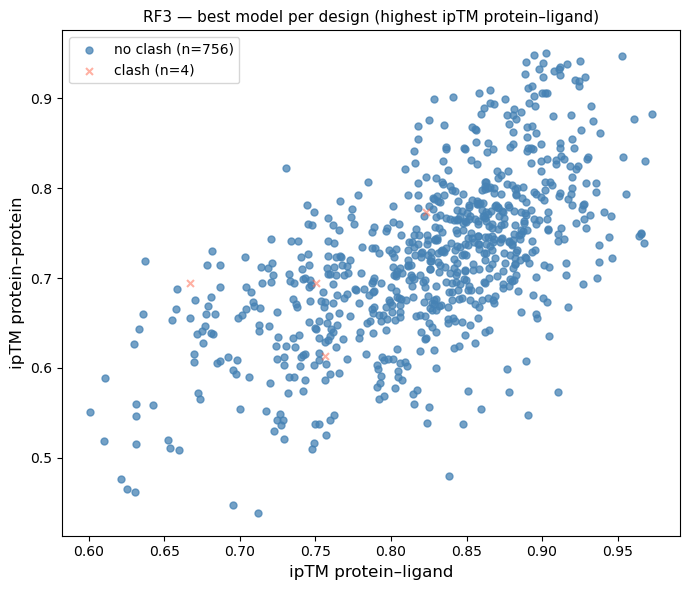

Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/pics/rf3_iptm_best.png


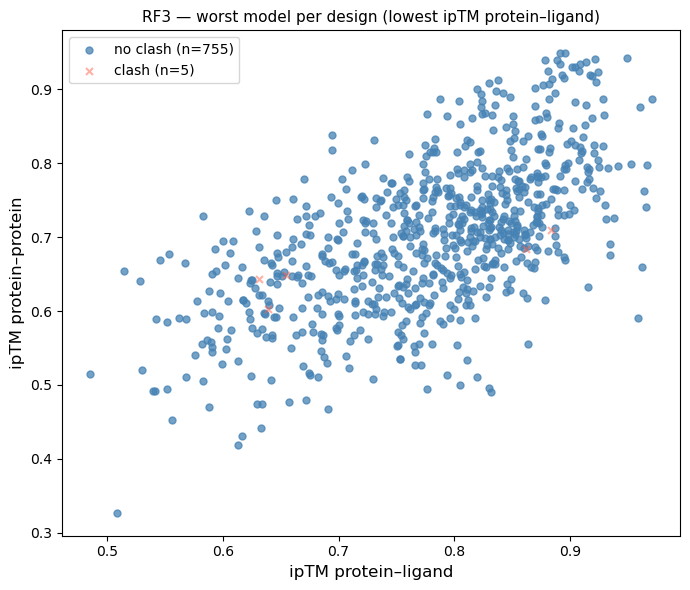

Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/pics/rf3_iptm_worst.png

Top designs (no clash in any model), ranked by best ipTM protein–ligand:


,example_id,best_iptm_pl,best_iptm_pp,best_clash,best_plddt,worst_iptm_pl,worst_iptm_pp,worst_clash,any_clash
476,ATP_binding_8btg_ATP_binding_8btg_6_model_0_6,0.972705,0.882305,0.0,0.875461,0.970896,0.887158,0.0,False
478,ATP_binding_8btg_ATP_binding_8btg_6_model_0_8,0.968246,0.830251,0.0,0.873303,0.966412,0.797723,0.0,False
471,ATP_binding_8btg_ATP_binding_8btg_6_model_0_1,0.967448,0.739399,0.0,0.821885,0.965726,0.740438,0.0,False
477,ATP_binding_8btg_ATP_binding_8btg_6_model_0_7,0.965756,0.748887,0.0,0.821651,0.959227,0.590328,0.0,False
470,ATP_binding_8btg_ATP_binding_8btg_6_model_0_10,0.965234,0.750392,0.0,0.852283,0.964411,0.762826,0.0,False
475,ATP_binding_8btg_ATP_binding_8btg_6_model_0_5,0.964300,0.747050,0.0,0.781412,0.962287,0.659659,0.0,False
473,ATP_binding_8btg_ATP_binding_8btg_6_model_0_3,0.960528,0.877011,0.0,0.848091,0.960207,0.876136,0.0,False
362,ATP_binding_8btg_ATP_binding_8btg_4_model_0_2,0.955393,0.792832,0.0,0.802984,0.952466,0.798754,0.0,False
533,ATP_binding_8btg_ATP_binding_8btg_6_model_6_3,0.953433,0.834642,0.0,0.728057,0.941233,0.796082,0.0,False
411,ATP_binding_8btg_ATP_binding_8btg_4_model_6_1,0.952972,0.947127,0.0,0.829276,0.949433,0.941831,0.0,False


In [14]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, f'{enzdes_scripts}/scripts/')
from rf3_sm_metrics import gather_rf3_small_molecule_metrics

N_MODELS = 5

# ── Collect all *_metrics.csv files ──────────────────────────────────────────
df = gather_rf3_small_molecule_metrics(
    parent    = rf3_out_dir,
    pattern   = '*_metrics.csv',
    n_models  = N_MODELS,
    add_stats = False,
)

# ── Per-design best / worst model (by iptm_protein_ligand) ───────────────────
pl_cols    = [f'iptm.iptm_protein_ligand_{i}' for i in range(N_MODELS)]
pp_cols    = [f'iptm.iptm_protein_protein_{i}' for i in range(N_MODELS)]
clash_cols = [f'count_clashing_chains.has_clash_{i}' for i in range(N_MODELS)]

pl_arr    = df[pl_cols].to_numpy(float)
pp_arr    = df[pp_cols].to_numpy(float)
clash_arr = df[clash_cols].to_numpy(float)

rows      = np.arange(len(df))
best_idx  = np.nanargmax(pl_arr, axis=1)
worst_idx = np.nanargmin(pl_arr, axis=1)

df['best_iptm_pl']  = pl_arr[rows, best_idx]
df['best_iptm_pp']  = pp_arr[rows, best_idx]
df['best_clash']    = clash_arr[rows, best_idx]

df['worst_iptm_pl'] = pl_arr[rows, worst_idx]
df['worst_iptm_pp'] = pp_arr[rows, worst_idx]
df['worst_clash']   = clash_arr[rows, worst_idx]

df['any_clash']     = (clash_arr > 0).any(axis=1)

#plDDT Extraction
import gzip
from Bio.PDB.MMCIFParser import MMCIFParser
from io import StringIO

def extract_mean_plddt_from_cif_gz(cif_gz_path):
    try:
        with gzip.open(cif_gz_path, 'rt') as f:
            content = f.read()
        parser = MMCIFParser(QUIET=True)
        structure = parser.get_structure('s', StringIO(content))
        bfactors = [
            atom.get_bfactor()
            for model in structure
            for chain in model
            for residue in chain
            for atom in residue
            if residue.id[0] == ' '
        ]
        return np.mean(bfactors) if bfactors else np.nan
    except Exception as e:
        print(f"Warning: could not parse {cif_gz_path}: {e}")
        return np.nan

def _best_cif_path(example_id, best_model_idx, rf3_out_dir):
    design_folder = example_id.rsplit('_', 1)[0]
    fname = f'{example_id}_model_{int(best_model_idx)}.cif.gz'
    return os.path.join(rf3_out_dir, design_folder, fname)

df['best_model_idx'] = best_idx
df['best_cif'] = df.apply(lambda r: _best_cif_path(r['example_id'], r['best_model_idx'], rf3_out_dir), axis=1)
df['best_plddt'] = df.apply(lambda r: extract_mean_plddt_from_cif_gz(r['best_cif']), axis=1)
print(f"pLDDT extracted for {df['best_plddt'].notna().sum()} / {len(df)} designs")

# ── Save CSV ──────────────────────────────────────────────────────────────────
summary_cols = [
    'example_id',
    'best_iptm_pl',  'best_iptm_pp',  'best_clash', 'best_plddt',
    'worst_iptm_pl', 'worst_iptm_pp', 'worst_clash',
    'any_clash',
]
out_csv = f'{scores_dir}/rf3_iptm_summary.csv'
df[summary_cols].to_csv(out_csv, index=False)
print(f"Saved: {out_csv}  ({len(df)} designs)")

n_no_clash = (~df['any_clash']).sum()
print(f"Designs with no clash in any model: {n_no_clash} / {len(df)}")

# ── Scatter plots ─────────────────────────────────────────────────────────────
def _scatter(df_plot, x_col, y_col, clash_col, title, out_path):
    no_clash  = df_plot[df_plot[clash_col] == 0]
    has_clash = df_plot[df_plot[clash_col] >  0]

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(no_clash[x_col],  no_clash[y_col],
               s=25, alpha=0.75, color='steelblue', label=f'no clash (n={len(no_clash)})')
    ax.scatter(has_clash[x_col], has_clash[y_col],
               s=25, alpha=0.5,  color='tomato',    label=f'clash (n={len(has_clash)})', marker='x')
    ax.set_xlabel('ipTM protein–ligand', fontsize=12)
    ax.set_ylabel('ipTM protein–protein', fontsize=12)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()
    print(f"Saved: {out_path}")

_scatter(df, 'best_iptm_pl',  'best_iptm_pp',  'best_clash',
         'RF3 — best model per design (highest ipTM protein–ligand)',
         f'{pics_dir}/rf3_iptm_best.png')

_scatter(df, 'worst_iptm_pl', 'worst_iptm_pp', 'worst_clash',
         'RF3 — worst model per design (lowest ipTM protein–ligand)',
         f'{pics_dir}/rf3_iptm_worst.png')

# ── Show top designs (no clash, ranked by best_iptm_pl) ──────────────────────
df_pass = df[~df['any_clash']].sort_values('best_iptm_pl', ascending=False)
print(f"\nTop designs (no clash in any model), ranked by best ipTM protein–ligand:")
display(df_pass[summary_cols].head(20))

#### Shortlisting — apply score cutoffs and copy best models

In [15]:
import shutil

# ── User-defined thresholds ───────────────────────────────────────────────────
iptm_pl_cutoff = 0.80   # minimum ipTM protein–ligand (best model)
iptm_pp_cutoff = 0.20   # minimum ipTM protein–protein (best model)
plddt_threshold = 0.70  # add this

# designs with any_clash == True are always excluded

shortlisted_dir     = f'{working_dir}/shortlisted'
shortlisted_structs = f'{shortlisted_dir}/structures'
os.makedirs(shortlisted_structs, exist_ok=True)

# ── Filter ────────────────────────────────────────────────────────────────────
df_short = df[
    (df['best_iptm_pl']  >= iptm_pl_cutoff) &
    (df['best_iptm_pp']  >= iptm_pp_cutoff) &
    (df['best_plddt']    >= plddt_threshold) &  # add this
    (~df['any_clash'])
].copy()
    
print(f"Shortlisted: {len(df_short)} / {len(df)} designs "
      f"(pl≥{iptm_pl_cutoff}, pp≥{iptm_pp_cutoff}, no clash)")

# ── Copy best model CIF for each passing design ───────────────────────────────

df_short['best_cif'] = df_short.apply(
    lambda r: _best_cif_path(r['example_id'], r['best_model_idx'], rf3_out_dir), axis=1)

missing = df_short['best_cif'].apply(lambda p: not os.path.exists(p)).sum()
if missing:
    print(f"WARNING: {missing} CIF file(s) not found — check rf3_out paths")

copied = 0
for _, row in df_short.iterrows():
    if os.path.exists(row['best_cif']):
        shutil.copy2(row['best_cif'],
                     os.path.join(shortlisted_structs, os.path.basename(row['best_cif'])))
        copied += 1
print(f"Copied {copied} CIFs → {shortlisted_structs}")

# ── Save shortlisted CSV ──────────────────────────────────────────────────────
shortlisted_csv = f'{shortlisted_dir}/shortlisted_scores.csv'
out_cols = summary_cols + ['best_model_idx', 'best_cif']
df_short[out_cols].to_csv(shortlisted_csv, index=False)
print(f"Saved: {shortlisted_csv}")


Shortlisted: 392 / 760 designs (pl≥0.8, pp≥0.2, no clash)
Copied 392 CIFs → /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/shortlisted/structures
Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/shortlisted/shortlisted_scores.csv


#### RF3 without ligand — test ligand dependence

In [16]:
# RF3 re-prediction without the ligand.
# Designs that score WORSE (lower iptm_pp) when the ligand is removed are
# ligand-dependent — these are the ones we want to keep.

nol_configs_dir = f'{shortlisted_dir}/rf3_nol_configs'
nol_out_dir     = f'{shortlisted_dir}/rf3_nol_out'
nol_cmds        = f'{cmds_dir}/rf3_nol.cmds'
os.makedirs(nol_configs_dir, exist_ok=True)
os.makedirs(nol_out_dir, exist_ok=True)

def _seqs_for_design(example_id, mpnn_out_dir, diffusion_out_dir):
    """Return {chain_id: seq} for the shortlisted design by re-parsing the MPNN FASTA."""
    mpnn_model, seq_idx = example_id.rsplit('_', 1)
    seq_idx = int(seq_idx)
    fastas = glob.glob(f'{mpnn_out_dir}/{mpnn_model}/seqs/*.cif.gz.fa')
    if not fastas:
        return None
    cif_matches = glob.glob(f'{diffusion_out_dir}/*/{mpnn_model}.cif.gz')
    chain_lens  = get_chain_lengths_from_cif(cif_matches[0]) if cif_matches else []
    for i, r in enumerate(SeqIO.parse(fastas[0], 'fasta')):
        if i == seq_idx:
            seq, pos, seqs = str(r.seq), 0, {}
            for chain_id, n_res in chain_lens:
                seqs[chain_id] = seq[pos:pos + n_res]
                pos += n_res
            return seqs
    return None

with open(nol_cmds, 'w') as f_out:
    skipped = 0
    for _, row in df_short.iterrows():
        eid  = row['example_id']
        seqs = _seqs_for_design(eid, mpnn_out_dir, diffusion_out_dir)
        if not seqs:
            print(f"WARNING: no sequence found for {eid}")
            skipped += 1
            continue

        json_f  = f'{nol_configs_dir}/{eid}.json'
        out_dir = f'{nol_out_dir}/{eid}'
        os.makedirs(out_dir, exist_ok=True)

        config = [{"name": eid, "components": [
            {"seq": seqs[c], "chain_id": c} for c in sorted(seqs)
            # ligand intentionally omitted
        ]}]
        with open(json_f, 'w') as jf:
            json.dump(config, jf, indent=4)

        cmd = (f'rf3 fold inference_engine=rf3 inputs={json_f} '
               f'out_dir={out_dir} ckpt_path={ckpt_path} '
               f'num_steps={num_steps} annotate_b_factor_with_plddt=True '
               f'early_stopping_plddt_threshold=0')
        f_out.write(cmd + '\n')

n_nol = len(open(nol_cmds).readlines())
jupyter_utils.make_sub_script(nol_cmds, n_task=n_nol, group_size=10, mem='10GB',
                              time_limit='4:00', cores=4,
                              gpu='num=1:mode=exclusive_process',
                              queue='gpul40s', job_name='rf3_nol',
                              env='/dtu/projects/dbl/rf3/release/conda_envs/rf3-env',
                              python_path='/dtu/projects/dbl/rf3/release')

sub_nol = nol_cmds.replace('.cmds', '.sh')
print(f"Generated {n_nol} no-ligand RF3 job(s)  (skipped {skipped}).")
print(f"\nSubmit with:\n  bsub < {sub_nol}\n")


Generated 392 no-ligand RF3 job(s)  (skipped 0).

Submit with:
  bsub < /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/cmds/rf3_nol.sh



#### Ligand-dependence filter — keep designs that need the ligand

Files: 333   Designs: 333   Failed files: 0
Ligand-dependent designs: 9 / 392 (nol iptm_pp < 0.5, iptm_pp ≥ 0.8)
Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/shortlisted/final_ligand_dependent.csv


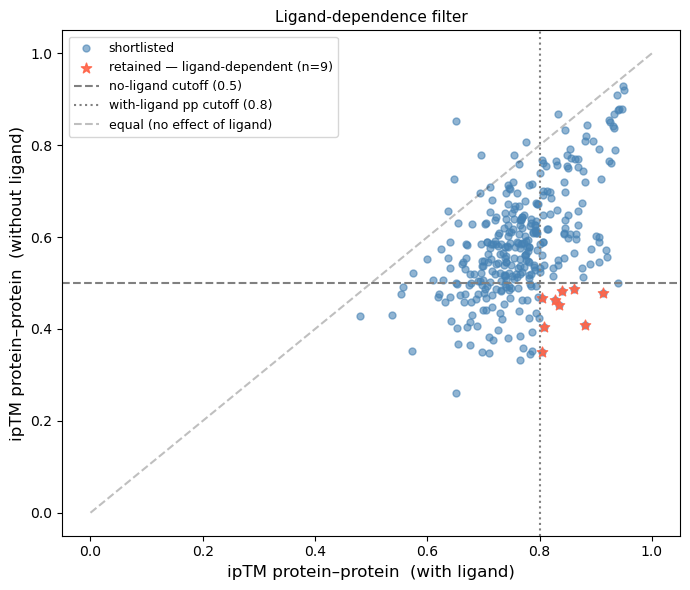

Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/pics/rf3_ligand_dependence.png


,example_id,best_iptm_pl,best_iptm_pp,best_iptm_pp_nol,best_cif
257,ATP_binding_8btg_ATP_binding_8btg_6_model_6_3,0.953433,0.834642,0.451970,/work3/s253573/projects/enzyme_design/atp_bind...
220,ATP_binding_8btg_ATP_binding_8btg_6_model_0_2,0.938375,0.861696,0.488076,/work3/s253573/projects/enzyme_design/atp_bind...
154,ATP_binding_8btg_ATP_binding_8btg_3_model_8_1,0.906914,0.880516,0.409114,/work3/s253573/projects/enzyme_design/atp_bind...
100,ATP_binding_8btg_ATP_binding_8btg_3_model_0_1,0.906497,0.803714,0.467955,/work3/s253573/projects/enzyme_design/atp_bind...
172,ATP_binding_8btg_ATP_binding_8btg_4_model_2_9,0.901830,0.806966,0.404349,/work3/s253573/projects/enzyme_design/atp_bind...
31,ATP_binding_8btg_ATP_binding_8btg_0_model_9_3,0.893420,0.913154,0.479245,/work3/s253573/projects/enzyme_design/atp_bind...
163,ATP_binding_8btg_ATP_binding_8btg_4_model_0_10,0.890195,0.840648,0.482776,/work3/s253573/projects/enzyme_design/atp_bind...
37,ATP_binding_8btg_ATP_binding_8btg_1_model_1_5,0.880287,0.803391,0.349673,/work3/s253573/projects/enzyme_design/atp_bind...
20,ATP_binding_8btg_ATP_binding_8btg_0_model_5_4,0.815693,0.827986,0.463640,/work3/s253573/projects/enzyme_design/atp_bind...


In [17]:
# ── User-defined thresholds ──────────────────────────────────────────────────
iptm_pp_nol_cutoff = 0.50   # MAXIMUM acceptable iptm_pp without ligand
                             # designs scoring ABOVE this are rejected (fold OK without ligand)
iptm_pp_cutoff     = 0.80   # MINIMUM acceptable iptm_pp with ligand (re-applied here for clarity)

# ── Collect no-ligand metrics ─────────────────────────────────────────────────
df_nol = gather_rf3_small_molecule_metrics(
    parent   = nol_out_dir,
    pattern  = '*_metrics.csv',
    n_models = N_MODELS,
    add_stats = False,
)

pp_cols_nol         = [f'iptm.iptm_protein_protein_{i}' for i in range(N_MODELS)]
pp_arr_nol          = df_nol[[c for c in pp_cols_nol if c in df_nol.columns]].to_numpy(float)
df_nol['best_iptm_pp_nol'] = np.nanmax(pp_arr_nol, axis=1)

# Merge with shortlisted df
df_merged = df_short.merge(df_nol[['example_id', 'best_iptm_pp_nol']],
                           on='example_id', how='left')

# Keep only ligand-dependent designs that also meet the with-ligand pp threshold
df_final = df_merged[
    (df_merged['best_iptm_pp_nol'] < iptm_pp_nol_cutoff) &
    (df_merged['best_iptm_pp']     >= iptm_pp_cutoff)
].copy()
print(f"Ligand-dependent designs: {len(df_final)} / {len(df_merged)} "
      f"(nol iptm_pp < {iptm_pp_nol_cutoff}, iptm_pp \u2265 {iptm_pp_cutoff})")

# ── Save final CSV ────────────────────────────────────────────────────────────
final_csv = f'{shortlisted_dir}/final_ligand_dependent.csv'
df_final.to_csv(final_csv, index=False)
print(f"Saved: {final_csv}")

# ── Scatter: with-ligand vs without-ligand iptm_pp ───────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df_merged['best_iptm_pp'], df_merged['best_iptm_pp_nol'],
           s=25, alpha=0.6, color='steelblue', label='shortlisted')
ax.scatter(df_final['best_iptm_pp'], df_final['best_iptm_pp_nol'],
           s=60, alpha=0.9, color='tomato', marker='*',
           label=f'retained — ligand-dependent (n={len(df_final)})')
ax.axhline(iptm_pp_nol_cutoff, color='gray', linestyle='--',
           label=f'no-ligand cutoff ({iptm_pp_nol_cutoff})')
ax.axvline(iptm_pp_cutoff, color='gray', linestyle=':',
           label=f'with-ligand pp cutoff ({iptm_pp_cutoff})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.25, label='equal (no effect of ligand)')
ax.set_xlabel('ipTM protein–protein  (with ligand)',    fontsize=12)
ax.set_ylabel('ipTM protein–protein  (without ligand)', fontsize=12)
ax.set_title('Ligand-dependence filter', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{pics_dir}/rf3_ligand_dependence.png', dpi=150)
plt.show()
print(f"Saved: {pics_dir}/rf3_ligand_dependence.png")

display(df_final[['example_id', 'best_iptm_pl', 'best_iptm_pp',
                  'best_iptm_pp_nol', 'best_cif']].sort_values(
    'best_iptm_pl', ascending=False).head(20))

#### RF3 monomer analysis — test single-chain binding

For each design that passed the ligand-dependence filter, re-fold each chain
**individually** in complex with the ligand. A design is only interesting if
*neither* chain can achieve high protein–ligand ipTM on its own — that would
mean the ligand binding site requires the full complex interface.

Two RF3 jobs are generated per design: **chain A + ligand** and **chain B + ligand**.

In [18]:
monomer_configs_dir = f'{shortlisted_dir}/rf3_monomer_configs'
monomer_out_dir     = f'{shortlisted_dir}/rf3_monomer_out'
monomer_cmds        = f'{cmds_dir}/rf3_monomer.cmds'
os.makedirs(monomer_configs_dir, exist_ok=True)
os.makedirs(monomer_out_dir, exist_ok=True)

skipped = 0
with open(monomer_cmds, 'w') as f_out:
    for _, row in df_final.iterrows():
        eid  = row['example_id']
        seqs = _seqs_for_design(eid, mpnn_out_dir, diffusion_out_dir)
        if not seqs:
            print(f"WARNING: no sequence found for {eid}")
            skipped += 1
            continue

        for chain_id, seq in sorted(seqs.items()):
            tag     = f'{eid}_mon{chain_id}'
            json_f  = f'{monomer_configs_dir}/{tag}.json'
            out_dir = f'{monomer_out_dir}/{tag}'
            os.makedirs(out_dir, exist_ok=True)

            config = [{"name": tag, "components": [
                {"seq": seq, "chain_id": chain_id},
                ligand_entry,
            ]}]
            with open(json_f, 'w') as jf:
                json.dump(config, jf, indent=4)

            cmd = (f'rf3 fold inference_engine=rf3 inputs={json_f} '
                   f'out_dir={out_dir} ckpt_path={ckpt_path} '
                   f'num_steps={num_steps} annotate_b_factor_with_plddt=True '
                   f'early_stopping_plddt_threshold=0')
            f_out.write(cmd + '\n')

n_mon = len(open(monomer_cmds).readlines())
jupyter_utils.make_sub_script(monomer_cmds, n_task=n_mon, group_size=10, mem='10GB',
                              time_limit='4:00', cores=4,
                              gpu='num=1:mode=exclusive_process',
                              queue='gpul40s', job_name='rf3_monomer',
                              env='/dtu/projects/dbl/rf3/release/conda_envs/rf3-env',
                              python_path='/dtu/projects/dbl/rf3/release')

sub_monomer = monomer_cmds.replace('.cmds', '.sh')
print(f"Generated {n_mon} monomer RF3 jobs for {len(df_final)} designs  (skipped {skipped}).")
print(f"\nSubmit with:\n  bsub < {sub_monomer}\n")

Generated 18 monomer RF3 jobs for 9 designs  (skipped 0).

Submit with:
  bsub < /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/cmds/rf3_monomer.sh



#### Monomer filter — keep designs where neither chain binds the ligand alone

Files: 18   Designs: 18   Failed files: 0
Designs passing monomer filter: 0 / 9 (both chains iptm_pl < 0.5)
Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/shortlisted/final_monomer_filtered.csv


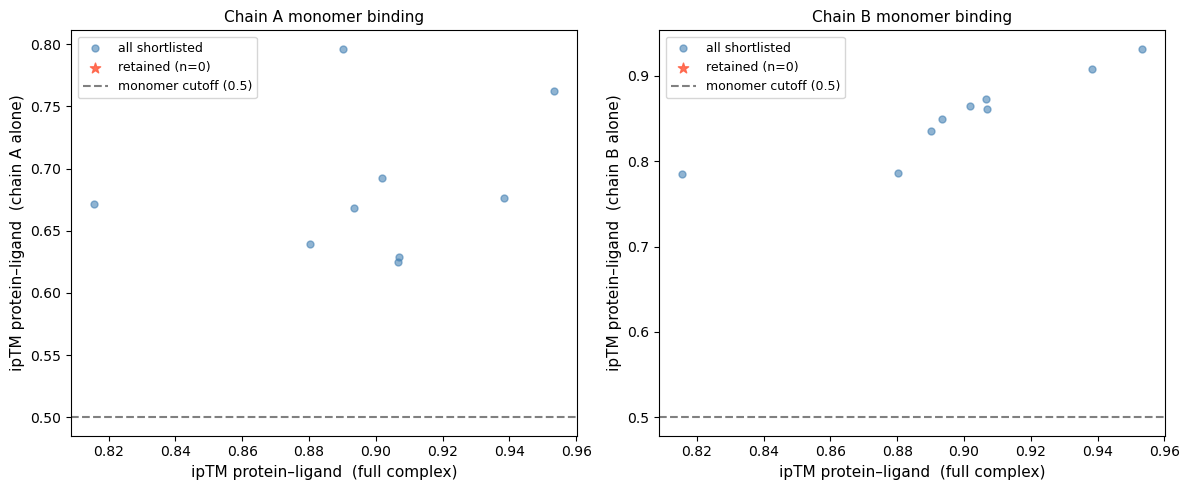

Saved: /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/pics/rf3_monomer_binding.png


,example_id,best_iptm_pl,best_iptm_pp,best_iptm_pp_nol,iptm_pl_monA,iptm_pl_monB,best_cif


In [19]:
# ── User-defined threshold ───────────────────────────────────────────────────
iptm_pl_monomer_cutoff = 0.50  # MAXIMUM acceptable iptm_pl for a single chain alone
                                # raise to be more permissive, lower to be stricter

# ── Collect monomer metrics ───────────────────────────────────────────────────
df_mon = gather_rf3_small_molecule_metrics(
    parent   = monomer_out_dir,
    pattern  = '*_metrics.csv',
    n_models = N_MODELS,
    add_stats = False,
)

pl_cols_mon = [f'iptm.iptm_protein_ligand_{i}' for i in range(N_MODELS)]
pl_arr_mon  = df_mon[[c for c in pl_cols_mon if c in df_mon.columns]].to_numpy(float)
df_mon['best_iptm_pl_mon'] = np.nanmax(pl_arr_mon, axis=1)

# Split example_id into original design ID and chain label (format: {eid}_mon{chain})
df_mon['design_id'] = df_mon['example_id'].str.rsplit('_mon', n=1).str[0]
df_mon['chain']     = df_mon['example_id'].str.rsplit('_mon', n=1).str[1]

# Pivot to one row per design with per-chain columns
df_monA = (df_mon[df_mon['chain'] == 'A'][['design_id', 'best_iptm_pl_mon']]
           .rename(columns={'design_id': 'example_id', 'best_iptm_pl_mon': 'iptm_pl_monA'}))
df_monB = (df_mon[df_mon['chain'] == 'B'][['design_id', 'best_iptm_pl_mon']]
           .rename(columns={'design_id': 'example_id', 'best_iptm_pl_mon': 'iptm_pl_monB'}))

df_final_mon = (df_final
                .merge(df_monA, on='example_id', how='left')
                .merge(df_monB, on='example_id', how='left'))

# Keep only designs where BOTH monomers score below the cutoff
df_final_mon_filt = df_final_mon[
    (df_final_mon['iptm_pl_monA'].fillna(0) < iptm_pl_monomer_cutoff) &
    (df_final_mon['iptm_pl_monB'].fillna(0) < iptm_pl_monomer_cutoff)
].copy()
print(f"Designs passing monomer filter: {len(df_final_mon_filt)} / {len(df_final_mon)} "
      f"(both chains iptm_pl < {iptm_pl_monomer_cutoff})")

# ── Save ──────────────────────────────────────────────────────────────────────
final_mon_csv = f'{shortlisted_dir}/final_monomer_filtered.csv'
df_final_mon_filt.to_csv(final_mon_csv, index=False)
print(f"Saved: {final_mon_csv}")

# ── Scatter: complex iptm_pl vs monomer iptm_pl per chain ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, chain, col in [(axes[0], 'A', 'iptm_pl_monA'), (axes[1], 'B', 'iptm_pl_monB')]:
    ax.scatter(df_final_mon['best_iptm_pl'], df_final_mon[col],
               s=25, alpha=0.6, color='steelblue', label='all shortlisted')
    ax.scatter(df_final_mon_filt['best_iptm_pl'], df_final_mon_filt[col],
               s=60, alpha=0.9, color='tomato', marker='*',
               label=f'retained (n={len(df_final_mon_filt)})')
    ax.axhline(iptm_pl_monomer_cutoff, color='gray', linestyle='--',
               label=f'monomer cutoff ({iptm_pl_monomer_cutoff})')
    ax.set_xlabel('ipTM protein–ligand  (full complex)', fontsize=11)
    ax.set_ylabel(f'ipTM protein–ligand  (chain {chain} alone)', fontsize=11)
    ax.set_title(f'Chain {chain} monomer binding', fontsize=11)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{pics_dir}/rf3_monomer_binding.png', dpi=150)
plt.show()
print(f"Saved: {pics_dir}/rf3_monomer_binding.png")

display(df_final_mon_filt[['example_id', 'best_iptm_pl', 'best_iptm_pp',
                            'best_iptm_pp_nol', 'iptm_pl_monA', 'iptm_pl_monB',
                            'best_cif']].sort_values('best_iptm_pl', ascending=False).head(20))

#### Final summary — ranked by ligand-dependent assembly

Combines all three filters into one table:
- **pp_drop**: how much the protein–protein ipTM drops when the ligand is removed (higher = more ligand-dependent)
- **iptm_pl_monA / monB**: how well each chain binds the ligand alone (lower = binding requires the full complex)
- **score**: composite rank = best_iptm_pl + pp_drop − avg_monomer_iptm_pl

In [20]:
# ── Composite ranking of ligand-dependent designs ───────────────────────────────────────
# df_final_mon is built in the cell above; re-run that cell first if needed.

df_summary = df_final_mon.copy()

df_summary["pp_drop"] = df_summary["best_iptm_pp"] - df_summary["best_iptm_pp_nol"]
df_summary["avg_mon"] = (df_summary["iptm_pl_monA"].fillna(1) +
                          df_summary["iptm_pl_monB"].fillna(1)) / 2
df_summary["score"]   = (df_summary["best_iptm_pl"] +
                          df_summary["pp_drop"] -
                          df_summary["avg_mon"])

show_cols = [
    "example_id",
    "best_iptm_pl",
    "best_iptm_pp",
    "best_iptm_pp_nol",
    "pp_drop",
    "iptm_pl_monA",
    "iptm_pl_monB",
    "avg_mon",
    "score",
    "best_cif",
]

df_ranked = (df_summary[show_cols]
             .sort_values("score", ascending=False)
             .reset_index(drop=True))
df_ranked.index += 1  # 1-based rank

with pd.option_context("display.max_colwidth", None,
                        "display.float_format", "{:.3f}".format):
    display(df_ranked)

print("\nStructure files (ranked):")
for rank, row in df_ranked.iterrows():
    print(f"  {rank}. {row['example_id']}\n     {row['best_cif']}")


,example_id,best_iptm_pl,best_iptm_pp,best_iptm_pp_nol,pp_drop,iptm_pl_monA,iptm_pl_monB,avg_mon,score,best_cif
1,ATP_binding_8btg_ATP_binding_8btg_3_model_8_1,0.907,0.881,0.409,0.471,0.629,0.862,0.745,0.633,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_3_model_8/ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.cif.gz
2,ATP_binding_8btg_ATP_binding_8btg_1_model_1_5,0.880,0.803,0.350,0.454,0.640,0.786,0.713,0.621,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_1_model_1/ATP_binding_8btg_ATP_binding_8btg_1_model_1_5_model_3.cif.gz
3,ATP_binding_8btg_ATP_binding_8btg_0_model_9_3,0.893,0.913,0.479,0.434,0.668,0.849,0.759,0.569,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_0_model_9/ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0.cif.gz
4,ATP_binding_8btg_ATP_binding_8btg_4_model_2_9,0.902,0.807,0.404,0.403,0.693,0.864,0.778,0.526,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_4_model_2/ATP_binding_8btg_ATP_binding_8btg_4_model_2_9_model_4.cif.gz
5,ATP_binding_8btg_ATP_binding_8btg_6_model_0_2,0.938,0.862,0.488,0.374,0.676,0.908,0.792,0.520,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_6_model_0/ATP_binding_8btg_ATP_binding_8btg_6_model_0_2_model_3.cif.gz
6,ATP_binding_8btg_ATP_binding_8btg_3_model_0_1,0.906,0.804,0.468,0.336,0.625,0.873,0.749,0.493,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_3_model_0/ATP_binding_8btg_ATP_binding_8btg_3_model_0_1_model_0.cif.gz
7,ATP_binding_8btg_ATP_binding_8btg_6_model_6_3,0.953,0.835,0.452,0.383,0.762,0.932,0.847,0.489,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_6_model_6/ATP_binding_8btg_ATP_binding_8btg_6_model_6_3_model_3.cif.gz
8,ATP_binding_8btg_ATP_binding_8btg_0_model_5_4,0.816,0.828,0.464,0.364,0.672,0.786,0.729,0.451,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_0_model_5/ATP_binding_8btg_ATP_binding_8btg_0_model_5_4_model_2.cif.gz
9,ATP_binding_8btg_ATP_binding_8btg_4_model_0_10,0.890,0.841,0.483,0.358,0.796,0.836,0.816,0.432,/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_4_model_0/ATP_binding_8btg_ATP_binding_8btg_4_model_0_10_model_0.cif.gz



Structure files (ranked):
  1. ATP_binding_8btg_ATP_binding_8btg_3_model_8_1
     /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_3_model_8/ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.cif.gz
  2. ATP_binding_8btg_ATP_binding_8btg_1_model_1_5
     /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_1_model_1/ATP_binding_8btg_ATP_binding_8btg_1_model_1_5_model_3.cif.gz
  3. ATP_binding_8btg_ATP_binding_8btg_0_model_9_3
     /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_0_model_9/ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0.cif.gz
  4. ATP_binding_8btg_ATP_binding_8btg_4_model_2_9
     /work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/rf3_out/ATP_binding_8btg_ATP_binding_8btg_4_model_2/ATP_binding_8btg_ATP_b